## Reproducing Fig. 2 of Feng, Zhang, Xiang (cond-mat/0610626)
Single Kitaev chain: (a) $-\partial^2E_0/\partial\gamma^2$, (b) string order parameters $\Delta_x,\Delta_y$, with $\gamma=J_1/J_2$.

In [1]:
# --- imports ---------------------------------------------------------------------------------
# SpinModelDM must be the version that contains the string-order methods
# (SpinSystem.string_order_limit, SpinSystem.chain_corr_matrix, ...).
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import quad
from SpinModelDM import SpinSystem

# --- parameters ------------------------------------------------------------------------------
J2          = 1.0          # gamma = J1/J2 is varied by changing J1 at fixed J2
L_RING      = 400          # periodic ring used for the string order (k-sum); must satisfy 2*JMAX <= L_RING-2
JMAX        = 40           # longest string: 2*JMAX sites;  Delta = mean |Delta(j)| over the last 3 j
E0_NORM     = 0.25         # energy-density normalisation of panel (a), see note below


In [2]:
# --- panel (a): -d^2 E0 / d gamma^2 ------------------------------------------------------------
# Single chain  H = sum_X J1 sx sx + sum_Y J2 sy sy  maps to free Majoranas with
#   E0 / N_sites = -(1/2pi) * Int_0^{2pi} dtheta sqrt(J1^2 + J2^2 + 2 J1 J2 cos(theta))
# so that  -d^2E0/dJ1^2 = (1/2pi) Int dtheta J2^2 sin^2(theta) / (J1^2+J2^2+2 J1 J2 cos theta)^{3/2},
# which diverges logarithmically at J1 = J2.   (E0_NORM = 1/4 is what reproduces the vertical scale of the
# paper's panel (a): 0.125 at gamma = 0, i.e. spin-1/2 operators S = sigma/2 instead of sigma.)
def minus_d2E0(J1, J2=1.0, norm=E0_NORM):
    f = lambda t: J2**2 * np.sin(t)**2 / (J1**2 + J2**2 + 2*J1*J2*np.cos(t))**1.5
    val, _ = quad(f, 0.0, np.pi, limit=400, points=[np.pi*(1 - 1e-6)] if abs(J1 - J2) < 1e-3 else None)
    return norm * val / np.pi          # (1/2pi) * 2 * Int_0^pi

gammas_a = np.linspace(0.0, 2.0, 800)             # never hits gamma = 1 exactly (log divergence)
curve_a  = np.array([minus_d2E0(g*J2, J2) for g in gammas_a])

# --- panel (b): string order parameters from the SpinSystem library ---------------------------
gammas_b = np.concatenate([np.linspace(0.02, 0.98, 30), np.linspace(1.02, 2.0, 30)])   # library points
Dx = np.zeros_like(gammas_b)
Dy = np.zeros_like(gammas_b)
for i, g in enumerate(gammas_b):
    s = SpinSystem(width=8, height=1, Jx=g*J2, Jy=J2, Jz=0)    # J1 = Jx, J2 = Jy;  Jz = 0 -> single chain
    cache = {}
    Dx[i] = s.string_order_limit('x', jmax=JMAX, tot_length=L_RING, cache=cache)   # Eq. (7)
    Dy[i] = s.string_order_limit('y', jmax=JMAX, tot_length=L_RING, cache=cache)   # Eq. (8)

# analytic Eq. (6): Delta_y = (1-gamma^2)^{1/4} for gamma<1,  Delta_x = (1-gamma^-2)^{1/4} for gamma>1.
# Near gamma = 1 the order parameters vanish like |gamma-1|^{1/4}, which strings of finite length cannot resolve,
# so the curves of panel (b) are drawn from Eq. (6) and the library numbers are overlaid as markers.
g_lo = 1 - np.logspace(-8, 0, 600)[::-1]            # 0 ... 1-1e-8 (dense toward 1)
g_hi = 1 + np.logspace(-8, 0, 600)                         # 1+1e-8 ... 2
Dy_curve = (1 - g_lo**2)**0.25
Dx_curve = (1 - g_hi**-2.0)**0.25
ana = np.array([SpinSystem.string_order_analytic(g*J2, J2) for g in gammas_b])
print("max |numerics - analytic|, gamma outside [0.9, 1.1]:",
      np.abs(np.hstack([Dx - ana[:, 0], Dy - ana[:, 1]])[np.tile(np.abs(gammas_b - 1) > 0.1, 2)]).max())


max |numerics - analytic|, gamma outside [0.9, 1.1]: 0.001510134015726853


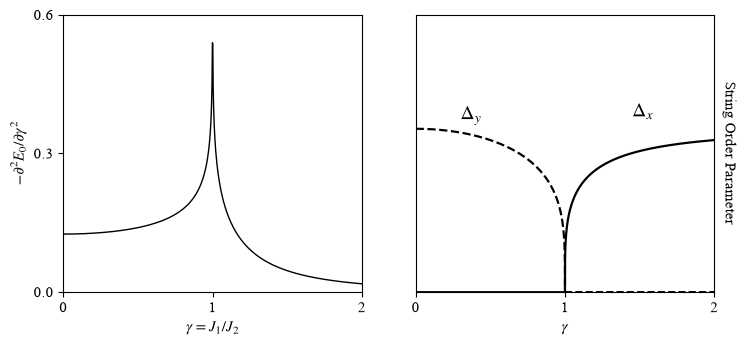

In [10]:
# --- plot ----------------------------------------------------------------------------------
plt.rcParams.update({
    "font.family": "serif",
    "font.serif": ["Times New Roman", "STIXGeneral"],   # STIXGeneral ships with matplotlib, used as a fallback
    "mathtext.fontset": "stix",                         # math symbols (γ, Δ, ∂, ...) in a Times-like face
    "font.size": 11,
})
fig, (axa, axb) = plt.subplots(1, 2, figsize=(8.4, 3.6), gridspec_kw={"wspace": 0.18})

# (a)
axa.plot(gammas_a, curve_a, "k-", lw=1)
axa.set(xlim=(0, 2), ylim=(0, 0.6), xticks=[0, 1, 2], yticks=[0.0, 0.3, 0.6],
        xlabel=r"$\gamma = J_1/J_2$", ylabel=r"$-\partial^2 E_0/\partial\gamma^2$")
# axa.text(0.06, 0.92, "(a)", transform=axa.transAxes, fontsize=14, va="top")

# (b)   Delta_y is plotted for gamma < 1 (dashed), Delta_x for gamma > 1 (solid), like in the paper;
# YMAX only sets the box height: the paper's panel (b) has no y tick labels, its curves reach ~0.59 of the box.
YMAX = 1.7
left, right = gammas_b < 1, gammas_b > 1
axb.plot(g_lo, Dy_curve, "k--", lw=1.6)                    # Eq. (6), Delta_y
axb.plot(g_hi, Dx_curve, "k-",  lw=1.6)                    # Eq. (6), Delta_x
# axb.plot(gammas_b[left],  Dy[left],  "o", mfc="none", mec="tab:red", ms=4, label="SpinSystem library")
# axb.plot(gammas_b[right], Dx[right], "o", mfc="none", mec="tab:red", ms=4)
# axb.plot([1, 1], [0, 0], "k.")
# RG-flow line along the bottom: flows to gamma = 0 for gamma < 1 and to gamma = infinity for gamma > 1
axb.plot([0, 1], [0, 0], "k-", lw=2);  axb.plot([1, 2], [0, 0], "k--", lw=1.4)
# axb.plot([0, 1], [0, 0], "ko", ms=6, clip_on=False)
# for x0, x1 in [(0.35, 0.2), (0.8, 0.65), (1.2, 1.35), (1.65, 1.8)]:
#     axb.annotate("", xy=(x1, 0), xytext=(x0, 0), arrowprops=dict(arrowstyle="-|>", color="k", lw=1.2, mutation_scale=12))
axb.text(0.30, 0.62*YMAX, r"$\Delta_y$", fontsize=14); axb.text(1.45, 0.63*YMAX, r"$\Delta_x$", fontsize=14)
# axb.legend(loc="lower right", bbox_to_anchor=(0.99, 0.08), frameon=False, fontsize=9)
# axb.text(0.06, 0.92, "(b)", transform=axb.transAxes, fontsize=14, va="top")
axb.set(xlim=(0, 2), ylim=(0, YMAX), xticks=[0, 1, 2], yticks=[], xlabel=r"$\gamma$")
axb.yaxis.set_label_position("right")
axb.set_ylabel("String Order Parameter", rotation=270, labelpad=16)
plt.show()
fig.savefig("figures/fig2_Feng-Zhang-Xiang.pdf", dpi=300, bbox_inches="tight")
